# AEGIS AI — Layer 2: Resource Allocation Engine
**Input:** Layer 1 output (flood probability, severity, population, % flooded area) + `resources.csv`, `depots.csv`, `districts_geo.csv`

**Run Layer 1 first** - it writes `layer1_output.csv` (all districts for one forecast date). Keep all files in the same folder as this notebook.
**Output:** district-wise allocation plan, depot dispatch plan, comparison of Greedy vs Linear Programming, and an interactive map.

Pipeline: load data → estimate demand → distance/ETA matrix → Greedy baseline → LP optimisation (SciPy HiGHS) → metrics → routes (Dijkstra) → map.

## 1. Setup

In [7]:
# Run once (remove the leading # if a library is missing)
# %pip install -q folium networkx scipy pandas numpy matplotlib

In [8]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import folium
from scipy.optimize import linprog
from scipy.sparse import lil_matrix
warnings.filterwarnings("ignore")

# ---- All files live in the same folder as this notebook ----
BASE_DIR = "."
print("Using folder:", os.path.abspath(BASE_DIR))

Using folder: C:\Users\ayush\Music\ML mini project v2


## 2. Configuration
Everything you may want to tune is here. Cite these as **assumptions** in your report.

In [9]:
# Layer 1 file: save your Layer 1 `layer1_output` (all districts) as CSV with this name
LAYER1_FILE = "layer1_output.csv"

PROB_THRESHOLD = 0.50      # districts with Flood_Probability >= this (or Flood_Occurred == 1) get relief
ROAD_FACTOR    = 1.30      # road distance ~= straight-line distance x 1.3
SPEED_KMPH     = 35        # average relief-convoy speed
LAMBDA_TRAVEL_FRAC = 0.5   # travel-time penalty strength: 0 = ignore distance, 1 = distance can cancel the lowest-priority gain
SHORTFALL_MULT = 10        # penalty multiplier for missing the Critical-district minimum guarantee
SEVERITY_WEIGHT = {"Low": 1, "Medium": 2, "High": 3, "Critical": 4}

# Units of each resource needed per AFFECTED PERSON (mirrors the Demand_Norm column of resources.csv)
DEMAND_RATE = {
    "RES01": 1/25000,   # rescue team: 1 per 25,000 people
    "RES02": 1/5000,    # rescue boat: 1 per 5,000 people
    "RES03": 1/50,      # medical kit: 1 per 50 people
    "RES04": 3,         # food packets: 1 per person per day x 3 days
    "RES05": 45,        # litres of water: 15 L per person per day x 3 days
    "RES06": 0.30,      # shelter slots: 30% of affected people displaced
}
# Depot stock share: NDRF battalions hold more than state depots
DEPOT_TYPE_WEIGHT = {"NDRF Battalion": 2.0, "State Depot": 1.0}

# ---- added for multi-district allocation ----
POOL_SCALE = 1.0            # multiplies every Total_Pool in resources.csv (0.5 = half, 2 = double). See section 13 for a sweep.
NONCRITICAL_MIN_FRAC = 0.5  # every flooded district is guaranteed at least this share of its FAIR share of the pool

## 3. Load supply-side files

In [10]:
resources = pd.read_csv(os.path.join(BASE_DIR, "resources.csv"))
depots    = pd.read_csv(os.path.join(BASE_DIR, "depots.csv"))
geo       = pd.read_csv(os.path.join(BASE_DIR, "districts_geo.csv"))

# ---- districts_geo.csv only has 4-5 states; the Layer 1 dataset has 30 districts in 10 states.
# These approximate district-centre coordinates fill the gap (State, District, Latitude, Longitude).
# Replace with exact values or add the rows to districts_geo.csv if you prefer.
EXTRA_GEO = [
    ("Assam", "Guwahati", 26.1445, 91.7362), ("Assam", "Silchar", 24.8333, 92.7789),
    ("Odisha", "Balasore", 21.4934, 86.9335), ("Odisha", "Cuttack", 20.4625, 85.8828),
    ("Odisha", "Kendrapara", 20.5013, 86.4222), ("Odisha", "Puri", 19.8135, 85.8312),
    ("Tamil Nadu", "Chennai", 13.0827, 80.2707),
    ("Uttar Pradesh", "Gorakhpur", 26.7606, 83.3732), ("Uttar Pradesh", "Lakhimpur Kheri", 27.9467, 80.7788),
    ("Uttar Pradesh", "Varanasi", 25.3176, 82.9739),
    ("West Bengal", "Malda", 25.0108, 88.1411), ("West Bengal", "Murshidabad", 24.1750, 88.2800),
    ("West Bengal", "North 24 Parganas", 22.6168, 88.4029),
    ("Jammu And Kashmir", "Srinagar", 34.0837, 74.7973),
    ("Gujarat", "Surat", 21.1702, 72.8311),
]
# Layer 1 spelling -> spelling used in districts_geo.csv
DISTRICT_ALIAS = {("maharashtra", "raigad"): "Raigarh", ("bihar", "saharsha"): "Saharsa"}

geo = pd.concat([geo, pd.DataFrame(EXTRA_GEO, columns=geo.columns)], ignore_index=True)

resources["rate"] = resources["Resource_ID"].map(DEMAND_RATE)
assert resources["rate"].notna().all(), "Add every Resource_ID to DEMAND_RATE"
display(resources[["Resource_ID","Resource_Name","Unit","Total_Pool","Priority_Weight","Min_Guarantee_Critical_Pct"]])
display(depots[["Depot_ID","Depot_Name","State","Depot_Type"]])
print("Districts with coordinates:", len(geo))

,Resource_ID,Resource_Name,Unit,Total_Pool,Priority_Weight,Min_Guarantee_Critical_Pct
0,RES01,Rescue Team,team,12,1.0,50
1,RES02,Rescue Boat,boat,60,0.9,50
2,RES03,Medical Kit,kit,6000,0.8,60
3,RES04,Food Packet,packet,900000,0.7,70
4,RES05,Drinking Water,litre,13500000,0.7,70
5,RES06,Shelter Slot,person-slot,90000,0.6,60


,Depot_ID,Depot_Name,State,Depot_Type
0,D01,NDRF 1st Bn Guwahati,Assam,NDRF Battalion
1,D02,NDRF 9th Bn Bihta (Patna),Bihar,NDRF Battalion
2,D03,NDRF 5th Bn Pune,Maharashtra,NDRF Battalion
3,D04,NDRF 4th Bn Arakkonam,Tamil Nadu,NDRF Battalion
4,D05,NDRF Bn Haringhata,West Bengal,NDRF Battalion
5,D06,NDRF 11th Bn Varanasi,Uttar Pradesh,NDRF Battalion
6,D07,State Depot Patna (SDRF),Bihar,State Depot
7,D08,State Depot Guwahati (SDRF),Assam,State Depot
8,D09,State Depot Mumbai (SDRF),Maharashtra,State Depot
9,D10,State Depot Thiruvananthapuram (SDRF),Kerala,State Depot


Districts with coordinates: 123


## 4. Load Layer 1 output
Expected columns: `District, Flood_Probability, Severity, Percent_Flooded_Area, Population` (optional: `Date_Time, Flood_Occurred, State, DFSI, Historical_Fatalities`).

If `layer1_output.csv` is not found, the notebook builds a **DEMO scenario** so you can test the full pipeline. Replace it with your real output before submitting.

In [11]:
def norm(s):
    return s.astype(str).str.strip().str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True)

l1_path = os.path.join(BASE_DIR, LAYER1_FILE)
USE_DEMO = not os.path.exists(l1_path)

if USE_DEMO:
    print("!! layer1_output.csv not found -> generating DEMO scenario. Run Layer 1 first for real results.")
    rng = np.random.default_rng(42)
    layer1 = geo.sample(14, random_state=7).copy()
    layer1["Flood_Probability"] = rng.beta(2.2, 1.6, len(layer1)).round(4)
    layer1["Population"] = rng.lognormal(13.9, 0.4, len(layer1)).astype(int)
    layer1["Percent_Flooded_Area"] = rng.uniform(3, 25, len(layer1)).round(1)
    layer1["Severity"] = pd.cut(layer1["Flood_Probability"], [0, .4, .65, .85, 1.01],
                                labels=["Low", "Medium", "High", "Critical"]).astype(str)
    layer1["Flood_Occurred"] = (layer1["Flood_Probability"] > 0.5).astype(int)
    layer1 = layer1[["State", "District", "Flood_Probability", "Flood_Occurred", "Severity",
                     "Percent_Flooded_Area", "Population"]]
else:
    layer1 = pd.read_csv(l1_path)
    layer1["District"] = layer1["District"].astype(str).str.strip()
    if "Date_Time" in layer1.columns:           # if several dates are present keep the latest per district
        layer1["Date_Time"] = pd.to_datetime(layer1["Date_Time"], errors="coerce")
        group_cols = ["State", "District"] if "State" in layer1.columns else ["District"]
        layer1 = layer1.sort_values("Date_Time").groupby(group_cols, as_index=False).tail(1)

need = ["District", "State", "Flood_Probability", "Severity", "Percent_Flooded_Area", "Population"]
missing = [c for c in need if c not in layer1.columns]
assert not missing, f"Layer 1 file is missing columns: {missing} (re-run the updated Layer 1 notebook)"
if "Flood_Occurred" not in layer1.columns:
    layer1["Flood_Occurred"] = (layer1["Flood_Probability"] >= PROB_THRESHOLD).astype(int)
print(f"Layer 1 file: {len(layer1)} districts in {layer1['State'].nunique()} states",
      "| date:", layer1["Date_Time"].max().date() if "Date_Time" in layer1.columns else "n/a")

# ---- attach coordinates (matched on State + District, so same-named districts in different states do not clash) ----
layer1["State"] = layer1["State"].astype(str).str.strip()
layer1["geo_name"] = [DISTRICT_ALIAS.get((s.lower(), d.lower()), d) for s, d in zip(layer1["State"], layer1["District"])]
layer1["key"] = norm(layer1["State"]) + "_" + norm(layer1["geo_name"])
geo["key"] = norm(geo["State"]) + "_" + norm(geo["District"])
geo_u = geo.drop_duplicates("key")[["key", "Latitude", "Longitude"]]
df = layer1.merge(geo_u, on="key", how="left")
unmatched = df[df["Latitude"].isna()][["State", "District"]].values.tolist()
if unmatched:
    print("No coordinates for (add them to EXTRA_GEO above):", unmatched)
df = df.dropna(subset=["Latitude", "Longitude"]).reset_index(drop=True)

# ---- districts that need relief ----
flood = df[(df["Flood_Probability"] >= PROB_THRESHOLD) | (df["Flood_Occurred"] == 1)].reset_index(drop=True)
flood["Sev_Weight"] = flood["Severity"].map(SEVERITY_WEIGHT).fillna(1)
print(f"{len(df)} districts loaded, {len(flood)} need relief")
assert len(flood) >= 2, ("Fewer than 2 districts need relief on this date - allocation is only meaningful for several "
                         "districts. Pick another SCENARIO_DATE in Layer 1.")
display(flood[["State", "District", "Flood_Probability", "Severity", "Percent_Flooded_Area", "Population"]])

Layer 1 file: 30 districts in 10 states | date: 2025-05-30
30 districts loaded, 9 need relief


,State,District,Flood_Probability,Severity,Percent_Flooded_Area,Population
0,Assam,Silchar,0.7619,Critical,19.8,229136
1,Kerala,Idukki,0.1753,Low,11.4,1108974
2,Kerala,Wayanad,0.2922,Medium,8.0,817420
3,Kerala,Alappuzha,0.2922,Medium,19.4,2127652
4,Assam,Lakhimpur,0.3434,Medium,8.6,1042137
5,Assam,Barpeta,0.4194,Medium,16.9,1693622
6,Kerala,Ernakulam,0.4194,Medium,18.1,3282388
7,Assam,Dhemaji,0.4194,High,13.6,686133
8,Assam,Guwahati,0.6333,High,15.3,1116257


## 5. Demand estimation
`Affected people = Population × (Percent_Flooded_Area / 100) × Flood_Probability`
`Demand(resource) = Affected people × units needed per person`

In [12]:
flood["Affected"] = flood["Population"] * flood["Percent_Flooded_Area"] / 100 * flood["Flood_Probability"]

R = resources["Resource_ID"].tolist()
rate = resources.set_index("Resource_ID")["rate"]
pool = resources.set_index("Resource_ID")["Total_Pool"] * POOL_SCALE
w_res = resources.set_index("Resource_ID")["Priority_Weight"]
min_pct = resources.set_index("Resource_ID")["Min_Guarantee_Critical_Pct"] / 100

demand = pd.DataFrame({r: flood["Affected"] * rate[r] for r in R})        # N x R
summary = pd.DataFrame({"Total_Demand": demand.sum(), "Pool": pool})
summary["Pool_vs_Demand_%"] = (summary["Pool"] / summary["Total_Demand"] * 100).round(1)
print(f"Total affected people: {flood['Affected'].sum():,.0f}")
display(summary.round(1))
cover = (summary["Pool"] / summary["Total_Demand"]).min()
if cover < 0.5:
    print(f"\nWARNING: the pool covers only {cover*100:.0f}% of estimated demand. Allocation will be a share-out of scarce stock "
          f"(see POOL_SCALE and section 13).")

Total affected people: 743,731


,Total_Demand,Pool,Pool_vs_Demand_%
RES01,29.7,12.0,40.3
RES02,148.7,60.0,40.3
RES03,14874.6,6000.0,40.3
RES04,2231192.7,900000.0,40.3
RES05,33467890.9,13500000.0,40.3
RES06,223119.3,90000.0,40.3


## 6. Depot stock and ETA matrix
Stock of each resource is split across depots by `DEPOT_TYPE_WEIGHT`. ETA = haversine distance × road factor ÷ speed.

In [13]:
def haversine(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2 +
         np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 12742 * np.arcsin(np.sqrt(a))

share = depots["Depot_Type"].map(DEPOT_TYPE_WEIGHT).fillna(1.0)
share = (share / share.sum()).values
stock = np.outer(share, pool[R].values)               # D x R

dist_km = haversine(depots["Latitude"].values[:, None], depots["Longitude"].values[:, None],
                    flood["Latitude"].values[None, :], flood["Longitude"].values[None, :]) * ROAD_FACTOR
eta_h = dist_km / SPEED_KMPH                           # D x N
D, N, K = len(depots), len(flood), len(R)
print("Depots:", D, "| Districts needing relief:", N, "| Resources:", K)
display(pd.DataFrame(eta_h.round(1), index=depots["Depot_ID"], columns=flood["District"]).iloc[:, :8])

Depots: 10 | Districts needing relief: 9 | Resources: 6


District,Silchar,Idukki,Wayanad,Alappuzha,Lakhimpur,Barpeta,Ernakulam,Dhemaji
Depot_ID,,,,,,,,
D01,6.7,88.5,85.2,91.4,9.8,2.9,89.3,12.7
D02,29.7,71.7,66.7,74.4,34.9,23.1,72.0,37.5
D03,77.4,39.0,30.6,40.1,85.1,73.3,37.6,87.9
D04,70.5,17.1,15.5,20.0,80.7,70.6,18.0,83.6
D05,17.8,70.6,67.5,73.5,27.3,17.2,71.4,30.2
D06,36.7,67.9,62.3,70.5,42.0,30.3,68.0,44.6
D07,28.7,72.3,67.3,75.0,33.9,22.1,72.6,36.5
D08,6.7,88.5,85.2,91.4,9.8,2.9,89.3,12.7
D09,79.8,41.4,33.0,42.4,87.2,75.4,39.9,90.0


## 7. Method A — Weighted Greedy baseline
Rank districts by `Severity weight × Flood probability × Affected people`. Serve the highest-priority district fully (from its nearest depots) before moving to the next.

In [14]:
priority = (flood["Sev_Weight"] * flood["Flood_Probability"] * flood["Affected"]).values
dem = demand.values                                    # N x K

def greedy_allocate():
    st = stock.copy()
    alloc = np.zeros((D, N, K))
    for i in np.argsort(-priority):
        for k in range(K):
            need = dem[i, k]
            for d in np.argsort(eta_h[:, i]):
                if need <= 1e-9:
                    break
                give = min(need, st[d, k])
                alloc[d, i, k] += give
                st[d, k] -= give
                need -= give
    return alloc

alloc_greedy = greedy_allocate()
print("Greedy allocation done.")

Greedy allocation done.


## 8. Method B — Linear Programming (SciPy / HiGHS)
**Decision variable:** `x[d,i,r]` = units of resource *r* sent from depot *d* to district *i*.

**Maximise**  Σ x · (w_r · Severity_i · Probability_i − λ · ETA_d,i) / rate_r  (value of covering people minus a small travel-time penalty).

**Subject to**
- Σᵢ x[d,i,r] ≤ Stock[d,r] (depot stock)
- Σ_d x[d,i,r] ≤ Demand[i,r] (never send more than needed)
- Σ_d x[d,i,r] + shortfall[i,r] ≥ Guarantee[i,r] (soft constraint, heavily penalised so the model stays feasible)

**Guarantee (new, scarcity-aware):** a district's *fair share* of the pool is `Pool × Affected_i / ΣAffected` (never more than its demand).
Critical districts are guaranteed `Min_Guarantee_Critical_Pct` of that fair share; **every other flooded district** is guaranteed `NONCRITICAL_MIN_FRAC` of it.
When the pool is large enough to cover everyone this is identical to the original "Critical ≥ x % of demand" rule; when the pool is small it stops one district from swallowing the whole pool.

In [15]:
def guarantee_matrix():
    """Guaranteed minimum per district and resource, in people-equivalents (units / rate)."""
    aff = flood["Affected"].values
    crit = (flood["Severity"] == "Critical").values
    mp = np.array([min_pct[r] for r in R])
    pool_pe = pool[R].values / np.array([rate[r] for r in R])            # people the whole pool could serve
    fair = np.minimum(aff[:, None], pool_pe[None, :] * aff[:, None] / aff.sum())
    frac = np.where(crit[:, None], mp[None, :], NONCRITICAL_MIN_FRAC)
    return frac * fair

def lp_allocate():
    # Work in "people-equivalents": y = units / rate, so every resource is on a comparable scale.
    sev = flood["Sev_Weight"].values
    prob_ = flood["Flood_Probability"].values
    aff = flood["Affected"].values
    rate_v = np.array([rate[r] for r in R])
    w_vec = np.array([w_res[r] for r in R])
    G = guarantee_matrix()
    min_gain = (w_vec.min() * sev * prob_).min()
    lam = LAMBDA_TRAVEL_FRAC * min_gain / eta_h.max()          # keeps every gain positive so stock is not wasted
    stock_p = stock / rate_v[None, :]                         # D x K  (people-equivalents)

    nx_ = D * N * K
    short_idx = {(i, k): nx_ + j for j, (i, k) in enumerate((i, k) for i in range(N) for k in range(K) if G[i, k] > 1e-9)}
    nvar = nx_ + len(short_idx)
    xi = lambda d, i, k: (d * N + i) * K + k

    c = np.zeros(nvar)
    for d in range(D):
        for i in range(N):
            for k in range(K):
                c[xi(d, i, k)] = -(w_vec[k] * sev[i] * prob_[i] - lam * eta_h[d, i])   # linprog minimises
    for (i, k), j in short_idx.items():
        c[j] = SHORTFALL_MULT * sev[i]

    rows = D * K + N * K + len(short_idx)
    A = lil_matrix((rows, nvar)); b = np.zeros(rows); r_ = 0
    for d in range(D):                                          # depot stock
        for k in range(K):
            for i in range(N):
                A[r_, xi(d, i, k)] = 1
            b[r_] = stock_p[d, k]; r_ += 1
    for i in range(N):                                          # never exceed demand
        for k in range(K):
            for d in range(D):
                A[r_, xi(d, i, k)] = 1
            b[r_] = aff[i]; r_ += 1
    for (i, k), j in short_idx.items():                         # guaranteed minimum (soft)
        for d in range(D):
            A[r_, xi(d, i, k)] = -1
        A[r_, j] = -1
        b[r_] = -G[i, k]; r_ += 1

    res = linprog(c, A_ub=A.tocsr(), b_ub=b, bounds=(0, None), method="highs")
    print("LP status:", res.message)
    y = res.x[:nx_].reshape(D, N, K)
    return y * rate_v[None, None, :]                            # back to real units

alloc_lp = lp_allocate()

LP status: Optimization terminated successfully. (HiGHS Status 7: Optimal)


## 9. Evaluation
Metrics from your project document: resource utilisation, population coverage, unmet demand (Critical districts below their minimum), and average response time.

Method,Weighted Greedy,Linear Programming
Population coverage %,40.3,40.3
Avg resource utilisation %,100.0,100.0
Critical districts below minimum,1.0,0.0
Flooded districts below guaranteed minimum,7.0,0.0
Districts with zero service,7.0,0.0
Avg response time (h),42.4,25.3


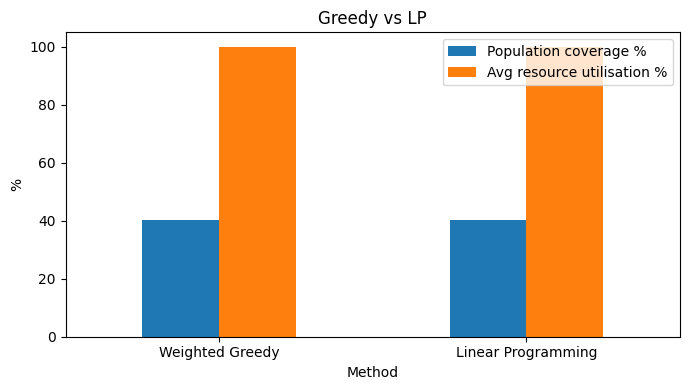

In [16]:
crit_mask = (flood["Severity"] == "Critical").values
w_vec = np.array([w_res[r] for r in R])
people_eq = np.array([1 / rate[r] for r in R])

def evaluate(alloc, name):
    given = alloc.sum(axis=0)                                   # N x K
    cov = np.divide(given, dem, out=np.zeros_like(given), where=dem > 0).clip(0, 1)
    dist_cov = (cov * w_vec).sum(axis=1) / w_vec.sum()          # weighted coverage per district
    pop_cov = (flood["Affected"].values * dist_cov).sum() / flood["Affected"].sum() * 100
    util = given.sum(axis=0) / pool[R].values * 100
    g_frac = guarantee_matrix() / flood["Affected"].values[:, None]       # guarantee as a fraction of demand
    min_ok = cov >= g_frac - 1e-6
    unmet = int((crit_mask & ~min_ok.all(axis=1)).sum())
    weights = alloc * people_eq[None, None, :]
    resp = (weights * eta_h[:, :, None]).sum() / max(weights.sum(), 1e-9)
    return {"Method": name,
            "Population coverage %": round(pop_cov, 1),
            "Avg resource utilisation %": round(util.mean(), 1),
            "Critical districts below minimum": unmet,
            "Flooded districts below guaranteed minimum": int((~min_ok.all(axis=1)).sum()),
            "Districts with zero service": int((dist_cov < 0.01).sum()),
            "Avg response time (h)": round(resp, 1)}

results = pd.DataFrame([evaluate(alloc_greedy, "Weighted Greedy"), evaluate(alloc_lp, "Linear Programming")])
display(results.set_index("Method").T)

ax = results.set_index("Method")[["Population coverage %", "Avg resource utilisation %"]].plot.bar(rot=0, figsize=(7, 4))
ax.set_title("Greedy vs LP"); ax.set_ylabel("%"); plt.tight_layout(); plt.show()

## 10. Allocation plan (district-wise) and dispatch plan (depot → district)

In [17]:
final = alloc_lp                                    # choose alloc_greedy to export the baseline instead
given = final.sum(axis=0)

plan = flood[["State", "District", "Severity", "Flood_Probability", "Population", "Affected"]].copy()
plan.index = flood.index
plan["Affected"] = plan["Affected"].round(0).astype(int)
for k, r in enumerate(R):
    name = resources.set_index("Resource_ID").loc[r, "Resource_Name"]
    plan[f"{name} allocated"] = given[:, k].round(1)
    plan[f"{name} cov%"] = np.where(dem[:, k] > 0, given[:, k] / dem[:, k] * 100, 0).round(0)
plan["_w"] = flood["Sev_Weight"].values          # sort Critical -> Low (alphabetical sorting was wrong)
plan = plan.sort_values(["_w", "Flood_Probability"], ascending=[False, False]).drop(columns="_w")
plan.to_csv(os.path.join(BASE_DIR, "layer2_allocation_plan.csv"), index=False)

rows = []
for d in range(D):
    for i in range(N):
        for k in range(K):
            if final[d, i, k] > 0.5:
                rows.append([depots["Depot_Name"][d], flood["District"][i], resources["Resource_Name"][k],
                             round(final[d, i, k], 1), round(dist_km[d, i], 0), round(eta_h[d, i], 1)])
dispatch = pd.DataFrame(rows, columns=["Depot", "District", "Resource", "Units", "Distance_km", "ETA_h"])
dispatch.to_csv(os.path.join(BASE_DIR, "layer2_dispatch_plan.csv"), index=False)
print("Saved layer2_allocation_plan.csv and layer2_dispatch_plan.csv")
display(plan.head(10))
display(dispatch.sort_values("Units", ascending=False).head(10))

Saved layer2_allocation_plan.csv and layer2_dispatch_plan.csv


,State,District,Severity,Flood_Probability,Population,Affected,Rescue Team allocated,Rescue Team cov%,Rescue Boat allocated,Rescue Boat cov%,Medical Kit allocated,Medical Kit cov%,Food Packet allocated,Food Packet cov%,Drinking Water allocated,Drinking Water cov%,Shelter Slot allocated,Shelter Slot cov%
0,Assam,Silchar,Critical,0.7619,229136,34567,1.4,100.0,6.9,100.0,691.3,100.0,103699.8,100.0,1555496.4,100.0,10370.0,100.0
8,Assam,Guwahati,High,0.6333,1116257,108160,4.3,100.0,21.6,100.0,2163.2,100.0,324478.8,100.0,4867182.5,100.0,32447.9,100.0
7,Assam,Dhemaji,High,0.4194,686133,39136,1.6,100.0,7.8,100.0,782.7,100.0,117407.8,100.0,1761116.8,100.0,11740.8,100.0
5,Assam,Barpeta,Medium,0.4194,1693622,120042,1.0,20.0,4.8,20.0,484.2,20.0,72632.0,20.0,1089480.7,20.0,7263.2,20.0
6,Kerala,Ernakulam,Medium,0.4194,3282388,249171,2.2,22.0,11.0,22.0,1101.4,22.0,165213.3,22.0,2478199.0,22.0,16521.3,22.0
4,Assam,Lakhimpur,Medium,0.3434,1042137,30777,0.2,20.0,1.2,20.0,124.1,20.0,18621.7,20.0,279326.1,20.0,1862.2,20.0
2,Kerala,Wayanad,Medium,0.2922,817420,19108,0.2,20.0,0.8,20.0,77.1,20.0,11561.4,20.0,173421.7,20.0,1156.1,20.0
3,Kerala,Alappuzha,Medium,0.2922,2127652,120610,1.0,20.0,4.9,20.0,486.5,20.0,72975.9,20.0,1094637.9,20.0,7297.6,20.0
1,Kerala,Idukki,Low,0.1753,1108974,22162,0.2,20.0,0.9,20.0,89.4,20.0,13409.3,20.0,201138.9,20.0,1340.9,20.0


,Depot,District,Resource,Units,Distance_km,ETA_h
4,NDRF 1st Bn Guwahati,Guwahati,Drinking Water,1687500.0,0.0,0.0
73,NDRF 11th Bn Varanasi,Dhemaji,Drinking Water,1687500.0,1562.0,44.6
62,NDRF Bn Haringhata,Silchar,Drinking Water,1555496.4,624.0,17.8
35,NDRF 5th Bn Pune,Ernakulam,Drinking Water,1242725.8,1314.0,37.6
56,NDRF 4th Bn Arakkonam,Ernakulam,Drinking Water,1235473.2,629.0,18.0
15,NDRF 9th Bn Bihta (Patna),Barpeta,Drinking Water,1089480.7,810.0,23.1
85,State Depot Guwahati (SDRF),Guwahati,Drinking Water,843750.0,0.0,0.0
97,State Depot Thiruvananthapuram (SDRF),Alappuzha,Drinking Water,843750.0,146.0,4.2
79,State Depot Patna (SDRF),Guwahati,Drinking Water,843750.0,862.0,24.6
91,State Depot Mumbai (SDRF),Guwahati,Drinking Water,843750.0,2712.0,77.5


## 11. Routing (Dijkstra)
A road graph is built from district centroids (each district connects to its nearest neighbours, each depot to its nearest districts). Dijkstra then finds the shortest route from a depot to a district. For real roads, replace this graph with an OpenStreetMap graph via `osmnx`.

In [18]:
G = nx.Graph()
all_pts = pd.concat([
    depots.assign(node="DEP_" + depots["Depot_ID"])[["node", "Latitude", "Longitude"]],
    geo.assign(node="DIS_" + geo["key"])[["node", "Latitude", "Longitude"]].drop_duplicates("node")   # key = state_district
]).reset_index(drop=True)
coords = all_pts[["Latitude", "Longitude"]].values
nodes = all_pts["node"].tolist()
dmat = haversine(coords[:, 0][:, None], coords[:, 1][:, None], coords[:, 0][None, :], coords[:, 1][None, :]) * ROAD_FACTOR

for a in range(len(nodes)):
    for b in np.argsort(dmat[a])[1:6]:                # 5 nearest neighbours
        G.add_edge(nodes[a], nodes[int(b)], weight=float(dmat[a, int(b)]))

def route(depot_id, district_key):
    src, dst = "DEP_" + depot_id, "DIS_" + district_key
    try:
        path = nx.dijkstra_path(G, src, dst, weight="weight")
        km = nx.dijkstra_path_length(G, src, dst, weight="weight")
        return path, km
    except Exception:
        return None, None
print("Routing graph:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

Routing graph: 133 nodes, 413 edges


## 12. Interactive map (open `aegis_layer2_map.html`)

In [19]:
sev_color = {"Low": "green", "Medium": "orange", "High": "red", "Critical": "darkred"}
m = folium.Map(location=[flood["Latitude"].mean(), flood["Longitude"].mean()], zoom_start=5, tiles="cartodbpositron")
fg_d = folium.FeatureGroup("Flood districts"); fg_p = folium.FeatureGroup("Depots"); fg_r = folium.FeatureGroup("Dispatch routes")

for i, row in flood.iterrows():
    g = plan.loc[i]                                   # plan keeps the same index as flood
    popup = (f"<b>{row['District']}</b> ({row['State']})<br>Severity: {row['Severity']}<br>"
             f"P(flood): {row['Flood_Probability']:.2f}<br>Affected: {int(row['Affected']):,}<br>" +
             "<br>".join(f"{resources['Resource_Name'][k]}: {given[i, k]:.0f} ({g.iloc[7 + 2*k]:.0f}% cov)" for k in range(K)))
    folium.CircleMarker([row["Latitude"], row["Longitude"]],
                        radius=5 + min(row["Affected"] / 40000, 15),
                        color=sev_color.get(row["Severity"], "gray"), fill=True, fill_opacity=0.7,
                        popup=folium.Popup(popup, max_width=300)).add_to(fg_d)

for _, dp in depots.iterrows():
    folium.Marker([dp["Latitude"], dp["Longitude"]], tooltip=dp["Depot_Name"],
                  icon=folium.Icon(color="blue", icon="plus-sign")).add_to(fg_p)

top = dispatch.groupby(["Depot", "District"], as_index=False)["Units"].sum().sort_values("Units", ascending=False).head(40)
dep_id = depots.set_index("Depot_Name")["Depot_ID"]
key_of = flood.set_index("District")["key"]
for _, r_ in top.iterrows():
    path, km = route(dep_id[r_["Depot"]], key_of[r_["District"]])
    if path:
        pts = [all_pts.set_index("node").loc[n, ["Latitude", "Longitude"]].tolist() for n in path]
        folium.PolyLine(pts, weight=2, color="blue", opacity=0.6,
                        tooltip=f"{r_['Depot']} -> {r_['District']} ({km:.0f} km)").add_to(fg_r)

for g_ in (fg_d, fg_p, fg_r): g_.add_to(m)
folium.LayerControl().add_to(m)
m.save(os.path.join(BASE_DIR, "aegis_layer2_map.html"))
m

## 13. Scenario test — how big must the pool be?
Re-runs Greedy and LP with the pool at different multiples of `Total_Pool` (replaces editing `resources.csv` by hand). Use this table in the report.

In [20]:
import contextlib, io
pool_base, stock_base = pool.copy(), stock.copy()
rows_ = []
for scale in [0.5, 1, 2, 5, 10]:
    pool = pool_base * scale
    stock = np.outer(share, pool[R].values)
    with contextlib.redirect_stdout(io.StringIO()):
        a_lp = lp_allocate()
    for name, a in (("Weighted Greedy", greedy_allocate()), ("Linear Programming", a_lp)):
        r_ = evaluate(a, name); r_["Pool x"] = scale; rows_.append(r_)
pool, stock = pool_base, stock_base                  # restore
sweep_df = pd.DataFrame(rows_).set_index(["Pool x", "Method"])
display(sweep_df)

Population coverage %  Avg resource utilisation %  \
Pool x Method                                                                  
0.5    Weighted Greedy                      20.2                       100.0   
       Linear Programming                   20.2                       100.0   
1.0    Weighted Greedy                      40.3                       100.0   
       Linear Programming                   40.3                       100.0   
2.0    Weighted Greedy                      80.7                       100.0   
       Linear Programming                   80.7                       100.0   
5.0    Weighted Greedy                     100.0                        49.6   
       Linear Programming                  100.0                        49.6   
10.0   Weighted Greedy                     100.0                        24.8   
       Linear Programming                  100.0                        24.8   

                           Critical districts below minimum  \
Pool x Method                                                 
0.5    Weighted Greedy                                    1   
       Linear Programming                                 0   
1.0    Weighted Greedy                                    1   
       Linear Programming                                 0   
2.0    Weighted Greedy                                    0   
       Linear Programming                                 0   
5.0    Weighted Greedy                                    0   
       Linear Programming                                 0   
10.0   Weighted Greedy                                    0   
       Linear Programming                                 0   

                           Flooded districts below guaranteed minimum  \
Pool x Method                                                           
0.5    Weighted Greedy                                              8   
       Linear Programming                                           0   
1.0    Weighted Greedy                                              7   
       Linear Programming                                           0   
2.0    Weighted Greedy                                              4   
       Linear Programming                                           0   
5.0    Weighted Greedy                                              0   
       Linear Programming                                           0   
10.0   Weighted Greedy                                              0   
       Linear Programming                                           0   

                           Districts with zero service  Avg response time (h)  
Pool x Method                                                                  
0.5    Weighted Greedy                               8                   57.6  
       Linear Programming                            0                   25.0  
1.0    Weighted Greedy                               7                   42.4  
       Linear Programming                            0                   25.3  
2.0    Weighted Greedy                               4                   28.2  
       Linear Programming                            0                   24.8  
5.0    Weighted Greedy                               0                   15.2  
       Linear Programming                            0                   14.2  
10.0   Weighted Greedy                               0                    9.2  
       Linear Programming                            0                    8.4

## 13. What to put in the report
- Greedy vs LP table (Section 9) — shows the benefit of optimisation.
- Scenario test: change `Total_Pool` in `resources.csv` to 50% / 100% / 150% and re-run.
- State assumptions clearly: resource pool sizes, per-person norms, speed, road factor, depot stock split.
- Future work: real road network (osmnx), multi-day rolling re-allocation, genetic algorithm for multi-objective trade-offs.